# 06 · Uplift Evaluation and Targeting Strategy

**Business question:** *if the company can contact only a limited share of customers, whom should
it contact to prevent the most churn?*

The answer depends on **incremental** impact, not on churn risk. A contact is only worth making if
it changes the outcome:

| Group | Without contact | With contact | Value of contacting |
|---|---|---|---|
| **Persuadables** | churn | stay | ✅ the only group where contact prevents churn |
| **Sure things** | stay | stay | wasted contact |
| **Lost causes** | churn | churn | wasted contact |
| **Sleeping dogs** | stay | churn | ❌ contact *causes* churn (e.g. it reminds customers to shop around) |

A churn-risk model ranks *lost causes and persuadables* together at the top. An uplift model tries
to rank *persuadables* first. Whether either ranking works can only be checked on the experiment:
within any group of customers, the treated-vs-control churn gap estimates that group's
incremental effect.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src.functions import (AQUA, BLUE, GREY, INK_2, ORANGE, OUTCOME, TREATMENT, area_vs_random,
                           bootstrap_targeting, build_sqlite, feature_lists, ipw_weights,
                           load_data, make_gbm_classifier, make_preprocessor, oof_predict_proba,
                           qini_coefficient, read_sql_queries, savefig, set_style,
                           targeting_value, uplift_by_group, uplift_curve)

set_style()
PROCESSED = ROOT / "data" / "processed"
df = load_data()
num, cat = feature_lists(df)
X = make_preprocessor(num, cat).fit_transform(df)
t, y = df[TREATMENT].to_numpy(), df[OUTCOME].to_numpy()
e = pd.read_parquet(PROCESSED / "propensity.parquet")["propensity"].to_numpy()
w = ipw_weights(t, e)
cate = pd.read_parquet(PROCESSED / "cate.parquet")

## 1. The competing strategies

* **Random:** contact a random k% of customers.
* **Churn risk:** contact the k% with the highest predicted churn probability. This is the
  conventional approach. The model is a cross-fitted gradient-boosting classifier of `y` on `X`.
  It is trained on all customers (treatment omitted), because the control arm alone has only 105
  churners. Since the treatment barely shifts churn on average, this is effectively a model of
  baseline risk.
* **Uplift (X-learner):** contact the k% with the largest estimated churn *reduction* (−τ̂).
  This is the main uplift model, the most coherent learner in notebook 05.
* **Uplift (T-learner)** and **Uplift (S-learner, logistic)** are included for comparison. The GBM
  S-learner is excluded because its CATE is zero for almost everyone, so it cannot rank customers.

All scores are out-of-fold predictions, so no customer is scored by a model that saw their outcome.

In [2]:
risk = oof_predict_proba(make_gbm_classifier, X, y, strata=2 * t + y, seed=0)
print(f"Churn-risk model, out-of-fold AUC: {roc_auc_score(y, risk):.3f}")

rng = np.random.default_rng(0)
scores = {
    "Random": rng.random(len(y)),
    "Churn risk": risk,
    "Uplift · X-learner": -cate["cate_x_gbm"].to_numpy(),
    "Uplift · T-learner": -cate["cate_t_gbm"].to_numpy(),
    "Uplift · S-learner (logistic)": -cate["cate_s_logit"].to_numpy(),
}
pd.DataFrame({k: v for k, v in scores.items() if k != "Random"}).corr(method="spearman").round(2)

Churn-risk model, out-of-fold AUC: 0.853


,Churn risk,Uplift · X-learner,Uplift · T-learner,Uplift · S-learner (logistic)
Churn risk,1.00,0.30,-0.27,-0.05
Uplift · X-learner,0.30,1.00,0.53,0.34
Uplift · T-learner,-0.27,0.53,1.00,0.37
Uplift · S-learner (logistic),-0.05,0.34,0.37,1.00


The churn-risk model is good at its own job (out-of-fold AUC 0.85). The uplift rankings are only
weakly related to churn risk, and only moderately related to each other. They are different rankings,
so the targeting strategies genuinely differ in *which* customers they would contact.

## 2. Do the rankings separate responders from non-responders?

Customers are split into deciles by each score. Within each decile the treated-vs-control churn
gap is computed, IPW-weighted to remove the segment-dependent assignment. A good uplift model
should show the **largest observed churn reduction in decile 1**, declining across deciles.

In [3]:
dec = {name: uplift_by_group(s, y, t, n_groups=10, w=w) for name, s in scores.items() if name != "Random"}
tab = pd.DataFrame({name: 100 * d["observed_reduction"].to_numpy() for name, d in dec.items()},
                   index=pd.Index(range(1, 11), name="decile (1 = highest score)"))
tab.round(2)

,Churn risk,Uplift · X-learner,Uplift · T-learner,Uplift · S-learner (logistic)
decile (1 = highest score),,,,
1,0.18,-1.28,0.35,-2.95
2,0.19,-0.74,-0.34,-1.32
3,0.59,-0.16,-0.01,1.17
4,-0.71,2.60,-0.90,-0.05
5,0.23,0.11,-0.32,-0.02
6,0.23,-0.61,0.03,-0.46
7,0.13,-0.06,0.71,-0.74
8,0.43,0.51,0.27,0.36
9,-0.21,-0.80,-2.52,1.32


In [4]:
cols = ["group", "n_control", "control_churners", "churn_control", "churn_treated", "observed_reduction", "se"]
pct = ["churn_control", "churn_treated", "observed_reduction", "se"]
for name in ["Churn risk", "Uplift · X-learner"]:
    print(name)
    display(dec[name][cols].assign(**{c: 100 * dec[name][c] for c in pct}).round(2).set_index("group"))

Churn risk


,n_control,control_churners,churn_control,churn_treated,observed_reduction,se
group,,,,,,
1,308,64,18.99,18.81,0.18,2.59
2,301,19,6.21,6.02,0.19,1.60
3,252,10,3.83,3.25,0.59,1.34
4,276,2,1.06,1.77,-0.71,0.76
5,256,3,1.44,1.21,0.23,0.83
6,308,3,1.07,0.84,0.23,0.66
7,305,2,0.86,0.73,0.13,0.60
8,340,2,1.04,0.60,0.43,0.61
9,282,0,0.00,0.21,-0.21,0.15


Uplift · X-learner


,n_control,control_churners,churn_control,churn_treated,observed_reduction,se
group,,,,,,
1,261,20,7.46,8.74,-1.28,1.87
2,303,15,4.51,5.24,-0.74,1.41
3,311,14,4.81,4.97,-0.16,1.42
4,310,15,4.76,2.15,2.60,1.30
5,281,7,2.65,2.54,0.11,1.09
6,267,4,1.48,2.09,-0.61,0.88
7,314,6,2.16,2.22,-0.06,0.96
8,305,8,2.25,1.74,0.51,0.96
9,278,4,1.10,1.90,-0.80,0.77


**What the deciles show**

* **Churn-risk ranking:** churn is heavily concentrated at the top (≈19% in decile 1 vs under
  0.5% in decile 10). The ranking finds *churners* very well. The churn gap between arms, however, is close to
  zero in every decile, including the top one: **18.99% control vs 18.81% treated**. High-risk
  customers churned at the same rate whether or not they were called, so they behave like
  *lost causes* rather than persuadables.
* **X-learner uplift ranking:** if the model worked, decile 1 would show the largest churn
  reduction. Instead, decile 1 shows churn **1.3 pp higher** among contacted customers, and there is
  no declining pattern across deciles. The single standout (decile 4, +2.6 pp, about 2 standard errors)
  is what one would expect by chance among 40 decile estimates.
* Every decile estimate rests on 0–64 control churners, which is why the intervals span several
  percentage points.

### The same decile table in SQL

For deployment, the scoring output would typically land in a database table. The query below
(from `sql/customer_summary.sql`) ranks customers with a window function and computes the
per-decile treated-vs-control comparison. It is unweighted, so its numbers differ slightly from
the IPW-weighted table above.

In [5]:
conn = build_sqlite(df)
pd.DataFrame({"customer_id": np.arange(len(y)), "uplift_score": scores["Uplift · X-learner"],
              "churn_risk": risk}).to_sql("scores", conn, index=False)
pd.read_sql(read_sql_queries()["uplift_deciles"], conn)

,decile,customers,treated,churn_control,churn_treated,observed_reduction
0,1,1190,929,0.0766,0.0861,-0.0095
1,2,1190,887,0.0495,0.0519,-0.0024
2,3,1190,879,0.0450,0.0489,-0.0039
3,4,1190,880,0.0484,0.0216,0.0268
4,5,1190,909,0.0249,0.0253,-0.0004
5,6,1190,923,0.0150,0.0206,-0.0056
6,7,1189,875,0.0191,0.0217,-0.0026
7,8,1189,884,0.0262,0.0181,0.0081
8,9,1189,911,0.0144,0.0187,-0.0043
9,10,1189,933,0.0469,0.0225,0.0244


## 3. Uplift curves and summary metrics

The **uplift curve** plots, for each fraction *k* of customers contacted in score order, the
estimated number of churners prevented: `[churn_control(k) − churn_treated(k)] × N(k)`. Random
targeting traces a straight line to the overall effect. The **area between a curve and the random
line** (normalised by N) summarises how much better than random a ranking is. Positive is better.
The **Qini coefficient** is the analogous area for the Qini curve. Its 95% CI comes from 500
bootstrap resamples. A **permutation p-value** compares each ranking against 500 random rankings
of the same data.

In [6]:
B = 500
boot_rng = np.random.default_rng(1)
idx_b = [boot_rng.integers(0, len(y), len(y)) for _ in range(B)]
perm_null = np.array([area_vs_random(boot_rng.random(len(y)), y, t, w) for _ in range(B)])

metrics = []
for name, s in scores.items():
    a = area_vs_random(s, y, t, w)
    a_b = np.array([area_vs_random(s[i], y[i], t[i], w[i]) for i in idx_b])
    metrics.append({"strategy": name, "uplift area vs random (×1000)": 1000 * a,
                    "95% CI low": 1000 * np.quantile(a_b, 0.025),
                    "95% CI high": 1000 * np.quantile(a_b, 0.975),
                    "Qini coef. (×1000)": 1000 * qini_coefficient(s, y, t, w),
                    "permutation p": (perm_null >= a).mean()})
metrics = pd.DataFrame(metrics).set_index("strategy")
metrics.round(3)

,uplift area vs random (×1000),95% CI low,95% CI high,Qini coef. (×1000),permutation p
strategy,,,,,
Random,-2.093,-4.717,0.235,-2.079,0.952
Churn risk,0.304,-2.451,3.065,0.303,0.420
Uplift · X-learner,-0.978,-3.449,1.541,-0.977,0.804
Uplift · T-learner,-0.823,-4.132,2.567,-0.824,0.770
Uplift · S-learner (logistic),-3.977,-7.183,-0.912,-3.977,1.000


**Reading the metrics**

* **No uplift model beats random targeting.** The X- and T-learner areas are slightly *negative*,
  with permutation p-values of ~0.8. A random ranking would do at least as well 80% of the time.
* The **logistic S-learner is worse than every one of the 500 random rankings**. Overfit CATE
  models can be actively harmful. A plausible mechanism is that, with no real signal, cross-fitted
  models learn the *training* folds' noise, and that noise is slightly anti-correlated with the
  held-out fold's noise.
* **Churn-risk targeting** has the only positive area, but it is small and well within chance
  (permutation p = 0.42).
* The "Random" row is a single random ranking. Its area (−2.1) is a useful reminder of the noise
  level: by luck alone, it is larger in magnitude than the area of every model except the overfit S-learner.

## 4. Targeting under a budget constraint

The central business comparison: if only 10%, 20% or 30% of customers can be contacted, how many
churners does each strategy prevent, relative to contacting nobody? Estimates are IPW-weighted,
with 95% bootstrap intervals (1,000 resamples, scores held fixed).

In [7]:
budgets = [0.1, 0.2, 0.3]
point = pd.DataFrame([{"strategy": name, **targeting_value(s, y, t, b, w)}
                      for name, s in scores.items() for b in budgets])
# Expected value of random targeting = overall (weighted) effect x number contacted
p1 = np.average(y[t == 1], weights=w[t == 1])
p0 = np.average(y[t == 0], weights=w[t == 0])
point.loc[point.strategy == "Random", "churners_prevented"] = (p0 - p1) * point.loc[point.strategy == "Random", "n_contacted"]
point.loc[point.strategy == "Random", "reduction_pp"] = 100 * (p0 - p1)
point.loc[point.strategy == "Random", ["churn_control", "churn_treated"]] = [p0, p1]

bt = bootstrap_targeting({k: v for k, v in scores.items() if k != "Random"}, y, t, budgets, w=w,
                         n_boot=1000, seed=2)
ci = bt.groupby(["strategy", "budget"])["churners_prevented"].quantile([0.025, 0.975]).unstack()
ci.columns = ["lo", "hi"]
prob_pos = bt.groupby(["strategy", "budget"])["churners_prevented"].apply(lambda v: (v > 0).mean()).rename("P(prevented > 0)")

# random targeting's CI: bootstrap of the overall effect
ate_b = []
for i in idx_b:
    yy, tt, ww = y[i], t[i], w[i]
    ate_b.append(np.average(yy[tt == 0], weights=ww[tt == 0]) - np.average(yy[tt == 1], weights=ww[tt == 1]))
ate_b = np.array(ate_b)
for b in budgets:
    n_k = int(round(b * len(y)))
    ci.loc[("Random", b), ["lo", "hi"]] = np.quantile(ate_b, [0.025, 0.975]) * n_k
    prob_pos.loc[("Random", b)] = (ate_b > 0).mean()

budget_tab = (point.set_index(["strategy", "budget"])[["n_contacted", "churn_control", "churn_treated",
                                                         "reduction_pp", "churners_prevented"]]
              .join(ci).join(prob_pos))
budget_tab["per 1,000 contacts"] = 1000 * budget_tab["churners_prevented"] / budget_tab["n_contacted"]
budget_tab.to_csv(PROCESSED / "budget_comparison.csv")
(budget_tab.assign(churn_control=100 * budget_tab.churn_control, churn_treated=100 * budget_tab.churn_treated)
           .round(2).sort_index(level=[1, 0]))

,,n_contacted,churn_control,churn_treated,reduction_pp,churners_prevented,lo,hi,P(prevented > 0),"per 1,000 contacts"
strategy,budget,,,,,,,,,
Churn risk,0.1,1190,18.99,18.81,0.18,2.18,-59.27,64.75,0.50,1.83
Random,0.1,1190,3.52,3.38,0.14,1.67,-7.80,11.51,0.62,1.40
Uplift · S-learner (logistic),0.1,1190,6.05,9.00,-2.95,-35.05,-76.04,3.86,0.04,-29.45
Uplift · T-learner,0.1,1190,7.45,7.10,0.35,4.17,-36.49,48.80,0.58,3.50
Uplift · X-learner,0.1,1190,7.46,8.74,-1.28,-15.22,-59.82,33.24,0.28,-12.79
Churn risk,0.2,2379,12.77,12.44,0.33,7.84,-66.26,83.70,0.59,3.30
Random,0.2,2379,3.52,3.38,0.14,3.33,-15.60,23.02,0.62,1.40
Uplift · S-learner (logistic),0.2,2379,4.08,6.15,-2.07,-49.24,-94.93,-1.83,0.02,-20.70
Uplift · T-learner,0.2,2379,4.38,4.38,0.00,0.06,-41.11,48.98,0.52,0.02


**At a 20% contact budget (2,379 customers):**

| Strategy | Estimated churners prevented | 95% CI |
|---|---|---|
| Random | ≈ 3 | −16 to +23 |
| Churn risk | ≈ 8 | −66 to +84 |
| Uplift · X-learner | ≈ −26 | −80 to +27 |
| Uplift · T-learner | ≈ 0 | −41 to +49 |

For these four strategies, every interval contains zero and every interval overlaps every
other, so **the data cannot distinguish between them**. The overfit logistic S-learner (not
shown) is the one strategy whose interval lies below zero: about −49 churners, i.e. it would
*increase* churn. Churn-risk targeting has the best point estimate at every
budget, and the X-learner the worst, but neither difference is statistically meaningful. The
intervals for the targeted strategies are wider than for random targeting because each estimate
relies on the few control customers inside the selected group.

## 5. Figures

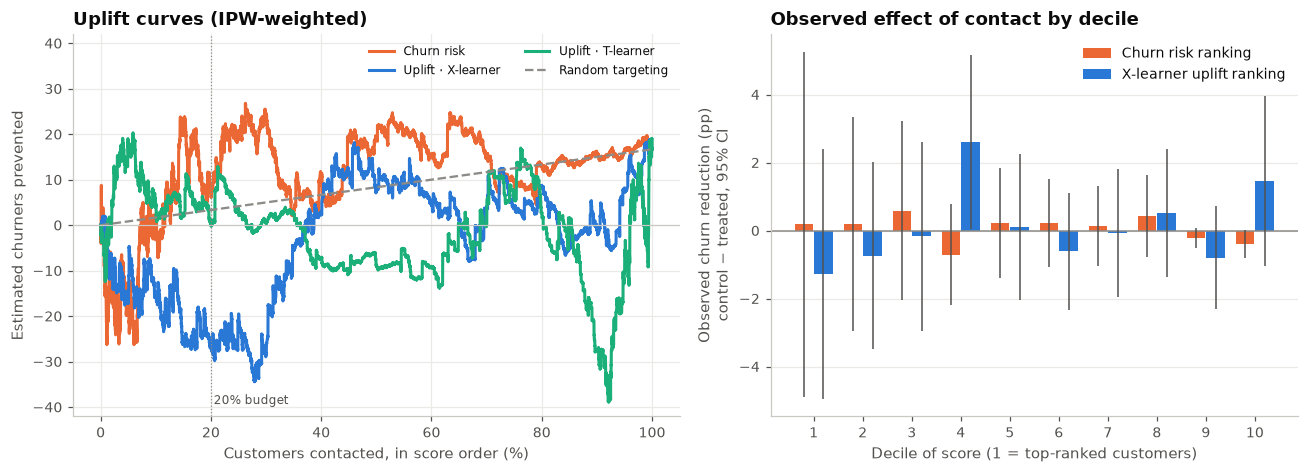

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1.15, 1]})
curve_styles = [("Churn risk", ORANGE), ("Uplift · X-learner", BLUE), ("Uplift · T-learner", AQUA)]
for name, colour in curve_styles:
    x, g = uplift_curve(scores[name], y, t, w)
    a1.plot(100 * x, g, color=colour, linewidth=2, label=name)
x, g = uplift_curve(scores["Uplift · X-learner"], y, t, w)
a1.plot([0, 100], [0, g[-1]], color=GREY, linewidth=1.5, linestyle="--", label="Random targeting")
a1.axhline(0, color="#c9c8c3", linewidth=0.8)
a1.axvline(20, color=GREY, linewidth=0.8, linestyle=":")
a1.text(20.5, -40, "20% budget", fontsize=8, color=INK_2, va="bottom")
a1.set_xlabel("Customers contacted, in score order (%)")
a1.set_ylabel("Estimated churners prevented")
a1.set_title("Uplift curves (IPW-weighted)")
a1.legend(loc="upper right", ncols=2, fontsize=8)
a1.set_ylim(-42, 42)

d_x, d_r = dec["Uplift · X-learner"], dec["Churn risk"]
xs = np.arange(1, 11)
a2.axhline(0, color=GREY, linewidth=1)
a2.bar(xs - 0.2, 100 * d_r.observed_reduction, width=0.38, color=ORANGE, label="Churn risk ranking")
a2.bar(xs + 0.2, 100 * d_x.observed_reduction, width=0.38, color=BLUE, label="X-learner uplift ranking")
a2.errorbar(xs - 0.2, 100 * d_r.observed_reduction, yerr=196 * d_r.se, fmt="none", ecolor=INK_2, elinewidth=1)
a2.errorbar(xs + 0.2, 100 * d_x.observed_reduction, yerr=196 * d_x.se, fmt="none", ecolor=INK_2, elinewidth=1)
a2.set_xticks(xs)
a2.set_xlabel("Decile of score (1 = top-ranked customers)")
a2.set_ylabel("Observed churn reduction (pp)\ncontrol − treated, 95% CI")
a2.set_title("Observed effect of contact by decile")
a2.legend(loc="upper right")
a2.grid(axis="x", visible=False)
plt.tight_layout()
savefig(fig, "fig7_uplift_curves")

**Reading the figure.** *Left:* each curve shows the estimated churners prevented as more
customers are contacted in the order a strategy ranks them. All curves end at the same point
(everyone contacted). A useful uplift model would rise steeply above the dashed random line early on
and stay above it. The real curves wander above and below the line with swings of ±30 churners.
Those swings are noise from the small number of control churners. The X-learner curve sits *below*
random for most of the first 40%. *Right:* the treated-vs-control churn gap within each decile.
Neither ranking produces the staircase pattern (large effect in decile 1, declining after) that
real heterogeneity would create.

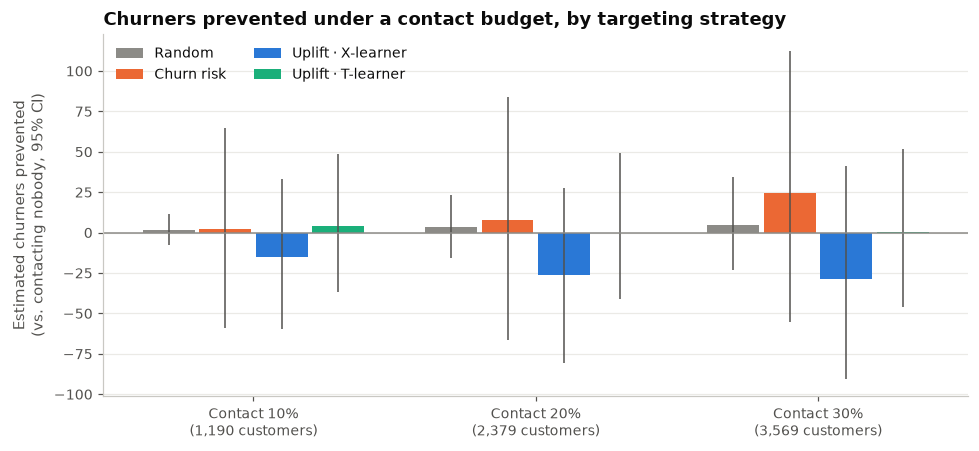

In [9]:
order = ["Random", "Churn risk", "Uplift · X-learner", "Uplift · T-learner"]
colours = {"Random": GREY, "Churn risk": ORANGE, "Uplift · X-learner": BLUE, "Uplift · T-learner": AQUA}
fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.2
for j, name in enumerate(order):
    sub = budget_tab.loc[name]
    xpos = np.arange(len(budgets)) + (j - 1.5) * width
    ax.bar(xpos, sub.churners_prevented, width=width * 0.92, color=colours[name], label=name)
    ax.errorbar(xpos, sub.churners_prevented,
                yerr=[sub.churners_prevented - sub.lo, sub.hi - sub.churners_prevented],
                fmt="none", ecolor=INK_2, elinewidth=1)
ax.axhline(0, color=GREY, linewidth=1)
ax.set_xticks(np.arange(len(budgets)), [f"Contact {int(100 * b)}%\n({int(round(b * len(y))):,} customers)" for b in budgets])
ax.set_ylabel("Estimated churners prevented\n(vs. contacting nobody, 95% CI)")
ax.set_title("Churners prevented under a contact budget, by targeting strategy")
ax.legend(loc="upper left", ncols=2)
ax.grid(axis="x", visible=False)
plt.tight_layout()
savefig(fig, "fig8_budget_comparison")

**Reading the figure.** Bars are point estimates of churners prevented at each budget and lines are
95% bootstrap intervals. The intervals dwarf the differences between bars. No strategy, including
uplift targeting, demonstrably prevents more churn than any other, or than contacting nobody.

## 6. Mapping customers to the four groups

Individual group membership can never be observed, because each customer has only one potential
outcome. The four groups can be approximated by crossing **baseline churn risk** (top 20% vs the
rest) with the **sign of the estimated effect** (X-learner: contact estimated to reduce vs
increase churn). The experiment then checks whether each cell behaves as its label claims.

In [10]:
high_risk = risk >= np.quantile(risk, 0.8)
helps = cate["cate_x_gbm"].to_numpy() < 0
cells = []
for r_lbl, r_mask in [("high risk (top 20%)", high_risk), ("lower risk", ~high_risk)]:
    for h_lbl, h_mask in [("τ̂ < 0: contact helps", helps), ("τ̂ ≥ 0: contact hurts", ~helps)]:
        m = r_mask & h_mask
        g = uplift_by_group(np.zeros(m.sum()), y[m], t[m], n_groups=1, w=w[m]).iloc[0]
        label = {("high risk (top 20%)", "τ̂ < 0: contact helps"): "Persuadables?",
                 ("high risk (top 20%)", "τ̂ ≥ 0: contact hurts"): "Lost causes / sleeping dogs?",
                 ("lower risk", "τ̂ < 0: contact helps"): "Persuadables (low base)?",
                 ("lower risk", "τ̂ ≥ 0: contact hurts"): "Sure things / sleeping dogs?"}[(r_lbl, h_lbl)]
        cells.append({"risk": r_lbl, "estimated effect": h_lbl, "label": label, "customers": int(m.sum()),
                      "control churners": int(((t == 0) & (y == 1) & m).sum()),
                      "churn control %": 100 * g.churn_control, "churn treated %": 100 * g.churn_treated,
                      "observed reduction (pp)": 100 * g.observed_reduction, "± 95% (pp)": 196 * g.se})
pd.DataFrame(cells).set_index(["risk", "estimated effect"]).round(2)

label  \
risk                estimated effect                                      
high risk (top 20%) τ̂ < 0: contact helps                 Persuadables?   
                    τ̂ ≥ 0: contact hurts  Lost causes / sleeping dogs?   
lower risk          τ̂ < 0: contact helps      Persuadables (low base)?   
                    τ̂ ≥ 0: contact hurts  Sure things / sleeping dogs?   

                                           customers  control churners  \
risk                estimated effect                                     
high risk (top 20%) τ̂ < 0: contact helps       1653                56   
                    τ̂ ≥ 0: contact hurts        727                27   
lower risk          τ̂ < 0: contact helps       4324                15   
                    τ̂ ≥ 0: contact hurts       5192                 7   

                                           churn control %  churn treated %  \
risk                estimated effect                                          
high risk (top 20%) τ̂ < 0: contact helps            13.05            13.55   
                    τ̂ ≥ 0: contact hurts            12.10             9.88   
lower risk          τ̂ < 0: contact helps             1.73             1.32   
                    τ̂ ≥ 0: contact hurts             0.65             0.98   

                                           observed reduction (pp)  ± 95% (pp)  
risk                estimated effect                                            
high risk (top 20%) τ̂ < 0: contact helps                    -0.50        3.79  
                    τ̂ ≥ 0: contact hurts                     2.22        5.16  
lower risk          τ̂ < 0: contact helps                     0.41        0.88  
                    τ̂ ≥ 0: contact hurts                    -0.33        0.55

**Reading the table.** If the four labels were right, the "persuadables" cell would show the
largest churn reduction and the "sleeping dogs" cells would show contact *increasing* churn. The
opposite happens in the high-risk row. Customers the X-learner says contact helps churned slightly
*more* when contacted (−0.5 pp), while those it says contact hurts churned *less* (+2.2 pp). All of
these differences are well within their ±4–5 pp margins. The four-group framework is the right way
to *think* about targeting, but this data cannot reliably assign customers to the groups.

## 7. Robustness and limitations

| Issue | Assessment for this project |
|---|---|
| **Randomisation** | Not unconditional. The treated share varies 63–86% across segments, consistent with pooled campaigns using different allocation ratios. Treated as random *given X*. Weighting by the propensity score achieves balance on all observed covariates (all \|SMD\| < 0.1), and adjusted ATEs barely differ from the raw one. Residual risk: if allocation depended on something unrecorded (e.g. agent judgement), no adjustment can fix it. |
| **SUTVA / interference** | Plausible but not testable. Household members or friends sharing contracts could influence each other's churn, and a contacted customer may mention an offer to a control customer, which would bias the effect towards zero. |
| **Treatment consistency** | Weak. "Treatment" is a call-centre contact whose offer, script and agent varied across campaigns and customers, and the data does not record which offer was made. The estimated effect is an average over a mix of interventions, and a good offer could be diluted by poor ones. |
| **Compliance** | Unknown. It is not recorded whether treated customers were actually reached. If many were not, the estimate is an *intention-to-treat* effect, smaller than the effect of a completed conversation. |
| **Outcome measurement** | Churn within two months is short. Effects that delay rather than prevent churn, or appear later, are missed. The outcome is consistently defined across arms, which is what matters for internal validity. |
| **Model misspecification** | The ATE does not depend on any model: the difference in means needs only randomisation. Regression estimates use a pre-specified covariate set, and AIPW is robust to misspecifying either model. CATE models are where misspecification bites, through the S-learner's regularisation bias and the T-learner's bias. |
| **Overfitting** | Controlled by cross-fitting: all scores are out-of-fold. Even so, the overfit logistic S-learner performed worse than random, and the learners' outputs are unstable across fold splits (rank correlation ≈ 0.6). |
| **Data leakage** | Features are described by the provider as measured before the campaign but cannot be verified. Within the pipeline, no model ever predicts a customer it was trained on. |
| **CATE uncertainty** | The dominant limitation. Only 105 control churners exist in total. The simulation in notebook 05 shows that heterogeneity of a realistic size is undetectable at this sample size *even when it exists*. |
| **Multiple testing** | Four learners × three budgets × ten deciles creates many chances for a spurious "win". Conclusions are drawn from pre-specified metrics, permutation tests and the overall pattern, not from the best-looking cell. |
| **External validity** | Telecom customers in Belgium in late 2020 (during COVID-19 restrictions), with a specific call-centre offer. A bank's customers, products, intervention and churn mechanism all differ. The *method* transfers, the *numbers* do not. |
| **Anonymised variables** | Even if a responsive segment had been found, it could only be described as e.g. "FACTOR4 = V10, high PC1". A business team could not act on that, check whether it makes sense, or design a better offer for it. |

## 8. Business recommendation

**1. Is the intervention effective?** Not demonstrably. Contacted customers churned at 3.36% vs
3.64% for the control group (−0.28 pp, 95% CI −1.10 to +0.46 pp, p = 0.48). Covariate-adjusted
estimates range from −0.13 to −0.44 pp, and none is significant. The experiment can rule out large
effects (a reduction of more than ~1.1 pp, or an increase of more than ~0.65 pp). It was only powered
(80%) to detect a reduction of about 1 pp, roughly a 29% cut in churn.

**2. Which customers are most responsive?** This cannot be determined from this data. Subgroup
effects and interaction terms are consistent with a single common effect. Machine-learning CATE
estimates are unstable across random splits, and when evaluated against the experiment they do not
identify customers with larger effects.

**3. Which targeting strategy performs best?** None is statistically distinguishable from random
targeting, or from contacting nobody. Churn-risk targeting has the best point estimates at every
budget, while uplift targeting does not outperform it and the X-learner ranking has the worst
point estimates.

**4. Under a 20% budget?** Estimated churners prevented: churn risk ≈ 8 (95% CI −66 to +84),
random ≈ 3, X-learner uplift ≈ −26. **Uplift-based targeting did not outperform churn-risk targeting.**

**Recommended actions**

* **Do not deploy the uplift model.** Its rankings do not validate on the experiment and would
  change materially if retrained.
* **Do not conclude that the campaign is worthless either.** The experiment was too small to detect
  the kind of effect (a few tenths of a percentage point) that could still be profitable for
  high-value customers. Whether it is depends on the cost per call and the margin per retained customer.
  As an illustration, at −0.28 pp, 1,000 calls prevent about 3 churners, so a call breaks even if it
  costs less than ~0.3% of the value of a retained customer.
* **If a campaign must run now, prioritise by churn risk as a working assumption, not a proven
  result.** If the campaign's effect is roughly proportional to baseline risk (a constant relative
  reduction, here an estimated risk ratio of 0.92), then contacting high-risk customers yields more
  absolute churn reduction per call. In the top-20% risk group (12.8% churn), an 8% relative
  reduction would prevent ~24 churners per 2,379 contacts, vs ~7 under random targeting. The
  experiment neither confirms nor refutes this assumption, and the observed top-decile gap (19.0%
  vs 18.8%) is a warning sign.

**5. Evidence needed before deployment**

* **A larger, cleanly designed experiment.** Use a single allocation ratio or explicit stratification
  by campaign, record the campaign identifier, offer type and whether the customer was reached, and
  choose the sample size from a power calculation. About 70,000 customers per arm are needed to
  detect −0.28 pp with 80% power. Detecting heterogeneity needs more.
* **Pre-registered uplift validation:** train the uplift model on this data, then test its top-k
  ranking in a *new* randomised trial in which the model's top decile and a random sample are both
  randomised. That is the only direct test of whether targeting by uplift adds value.
* **Interpretable features.** With named variables (tenure, product holdings, recent complaints,
  price changes), candidate responsive segments could be stated as hypotheses in advance and tested,
  rather than discovered in anonymised components.